# 01. Dataset Overview

**Dataset:** CycPeptMPDB

**Goal:** Explore the dataset and assess its suitability for PepGate.

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data_path = Path("../data/raw/CycPeptMPDB_Peptide_All.csv")
df = pd.read_csv(data_path, encoding="utf-8-sig", low_memory=False)

### Q. How many records and features are in the dataset?

In [3]:
print(f"Records: {df.shape[0]:,}")
print(f"Features: {df.shape[1]}")

# Preview relevant columns
cols = [
    "ID", "Source", "Year", "SMILES", "HELM",
    "Monomer_Length", "Molecule_Shape",
    "PAMPA", "Caco2", "MDCK", "RRCK"
]

display(df[cols].head())

Records: 8,466
Features: 247


,ID,Source,Year,SMILES,HELM,Monomer_Length,Molecule_Shape,PAMPA,Caco2,MDCK,RRCK
0,1,2006_Rezai_1,2006,C/C=C/C[C@@H](C)[C@@H](O)[C@H]1C(=O)N[C@@H](CC...,PEPTIDE1{[Abu].[Sar].[meL].V.[meL].A.[dA].[meL...,11,Circle,-6.6,NaN,NaN,NaN
1,2,2006_Rezai_1,2006,CC(C)C[C@@H]1NC(=O)[C@@H](CC(C)C)NC(=O)[C@@H](...,"PEPTIDE2{[dL].[dL].L.[dL].P.Y}$PEPTIDE2,PEPTID...",6,Circle,-6.2,NaN,NaN,NaN
2,3,2006_Rezai_1,2006,CC(C)C[C@H]1NC(=O)[C@H](Cc2ccc(O)cc2)NC(=O)[C@...,"PEPTIDE3{[dL].[dL].[dL].[dL].P.Y}$PEPTIDE3,PEP...",6,Circle,-7.0,NaN,NaN,NaN
3,4,2006_Rezai_1,2006,CC(C)C[C@@H]1NC(=O)[C@H](CC(C)C)NC(=O)[C@H](Cc...,"PEPTIDE4{L.L.L.[dL].P.Y}$PEPTIDE4,PEPTIDE4,1:R...",6,Circle,-7.1,NaN,NaN,NaN
4,5,2006_Rezai_1,2006,CC(C)C[C@@H]1NC(=O)[C@H](Cc2ccc(O)cc2)NC(=O)[C...,"PEPTIDE5{L.[dL].[dL].[dL].P.Y}$PEPTIDE5,PEPTID...",6,Circle,-7.2,NaN,NaN,NaN


### Q. How many permeability measurements are available for each assay?

In [4]:
assays = ["PAMPA", "Caco2", "MDCK", "RRCK"]

coverage = pd.DataFrame({
    "Available": df[assays].notna().sum(),
    "Missing": df[assays].isna().sum()
})

coverage["Coverage (%)"] = (coverage["Available"] / len(df) * 100).round(1)

display(coverage)

,Available,Missing,Coverage (%)
PAMPA,7298,1168,86.2
Caco2,1332,7134,15.7
MDCK,64,8402,0.8
RRCK,186,8280,2.2


### Q. What are the distributions of peptide lengths, topologies, and data sources?

In [6]:
# sequence len
print("Peptide lengths:")
display(df["Monomer_Length"].value_counts().sort_index())

# peptide topologies
print("Molecular topologies:")
display(df["Molecule_Shape"].value_counts())

# data sources
print("Number of sources:", df["Source"].nunique())
print("\nTop 10 sources:")
display(df["Source"].value_counts().head(10))

Peptide lengths:


Monomer_Length
2        4
3       69
4       55
5       88
6     2167
7     2071
8      120
9      423
10    1777
11     675
12     632
13     234
14     125
15      26
Name: count, dtype: int64

Molecular topologies:


Molecule_Shape
Circle    5530
Lariat    2936
Name: count, dtype: int64

Number of sources: 56

Top 10 sources:


Source
2020_Townsend    3086
2021_Kelly       1519
2013_CHUGAI       878
2016_Furukawa     688
2023_Ohta         584
2018_CHUGAI       374
2024_Faris        234
2022_Bhardwaj     136
2018_Naylor        81
2015_Wang          62
Name: count, dtype: int64

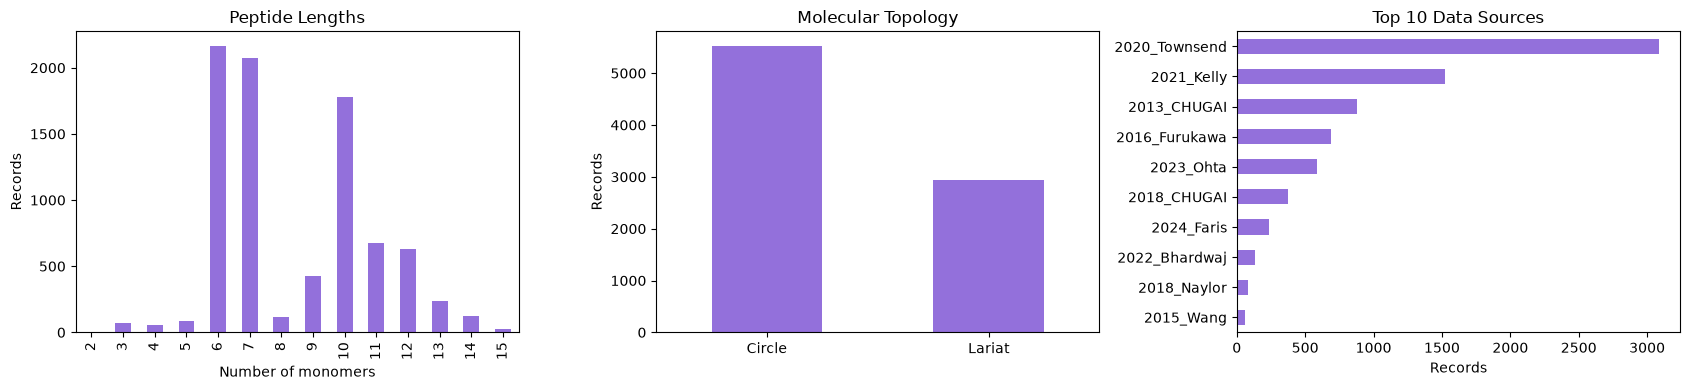

In [7]:
# visiualize 

fig, axes = plt.subplots(1, 3, figsize=(17, 4))


df["Monomer_Length"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0], color="mediumpurple"
)
axes[0].set(title="Peptide Lengths", xlabel="Number of monomers", ylabel="Records")


df["Molecule_Shape"].value_counts().plot(
    kind="bar", ax=axes[1], color="mediumpurple"
)
axes[1].set(title="Molecular Topology", xlabel="", ylabel="Records")
axes[1].tick_params(axis="x", rotation=0)


df["Source"].value_counts().head(10).sort_values().plot(
    kind="barh", ax=axes[2], color="mediumpurple"
)
axes[2].set(title="Top 10 Data Sources", xlabel="Records", ylabel="")

plt.tight_layout()
plt.show()


- Most peptides have 6, 7, or 10 monomers.
- 65.3% are classified as Circle.
- The two largest sources contribute 54.4% of all records.

### Q. How are permeability values distributed across assays?

#### Permeability is commonly expressed on a logarithmic scale:

$$
\log_{10}(P_{\mathrm{app}})
$$

In [8]:
# summary stat for each assay
display(df[assays].describe().round(2))

,PAMPA,Caco2,MDCK,RRCK
count,7298.00,1332.00,64.00,186.00
mean,-5.91,-6.23,-5.57,-5.68
std,1.12,0.92,0.76,0.71
min,-10.00,-10.00,-7.70,-10.00
25%,-6.26,-6.85,-6.13,-6.14
50%,-5.69,-6.01,-5.40,-5.59
75%,-5.25,-5.66,-5.03,-5.19
max,-3.90,-3.46,-4.40,-4.49


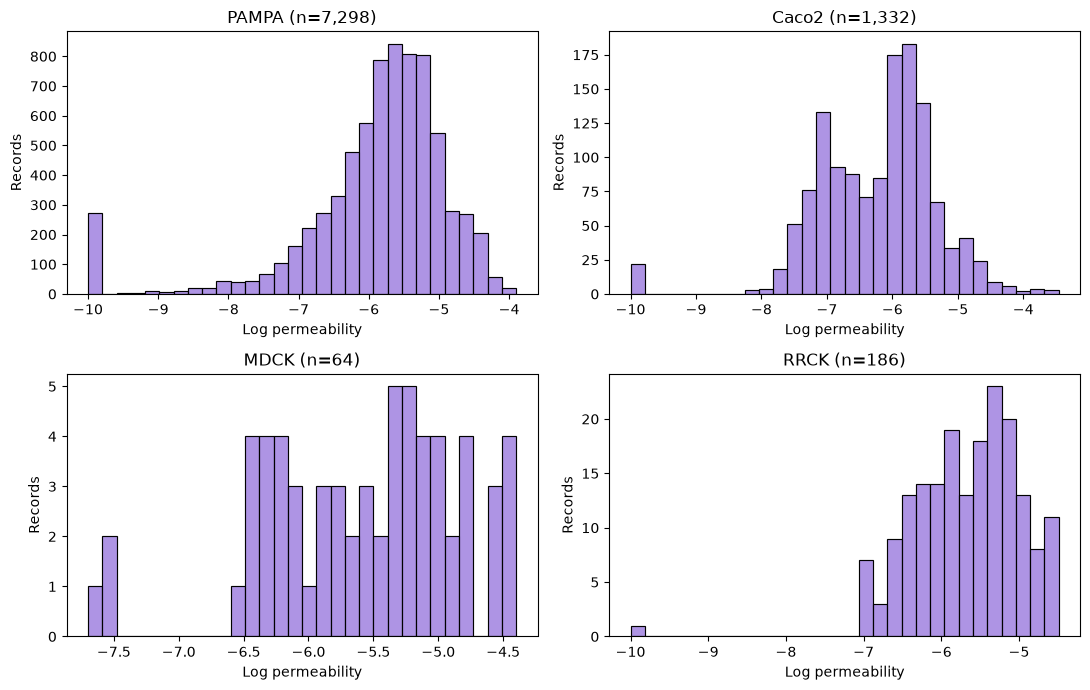

In [9]:

fig, axes = plt.subplots(2, 2, figsize=(11, 7))

for ax, assay in zip(axes.flat, assays):
    values = df[assay].dropna()

    sns.histplot(values, bins=30, ax=ax, color="mediumpurple")
    ax.set(
        title=f"{assay} (n={len(values):,})",
        xlabel="Log permeability",
        ylabel="Records"
    )

plt.tight_layout()
plt.show()


In [10]:
# checking values at -10 (below detection limit? maybe?)
for assay in assays:
    values = df[assay].dropna()
    print(f"{assay}: {(values == -10).sum()} values at -10")


PAMPA: 271 values at -10
Caco2: 22 values at -10
MDCK: 0 values at -10
RRCK: 1 values at -10


- PAMPA has the most measurements and a broad permeability range.
- Caco-2 shows a potentially multimodal distribution.
- Several values occur at -10 which may indicate detection limits.

TODO: check doucmentation to confirm detection limits

### Q. Are there duplicate peptides or repeated measurements?

In [11]:
# count repeated structures
structure_counts = df["Structurally_Unique_ID"].value_counts()

print("Unique structures:", structure_counts.size)
print("Structures appearing more than once:", (structure_counts > 1).sum())
print("Records belonging to repeated structures:", structure_counts[structure_counts > 1].sum())

# most frequent repeated structure
display(structure_counts.head(10))


Unique structures: 7991
Structures appearing more than once: 437
Records belonging to repeated structures: 912


Structurally_Unique_ID
25      10
1        9
10       7
138      3
452      3
453      3
1000     3
1001     3
1002     3
1003     3
Name: count, dtype: int64

In [12]:
# inspect structure 25
example = df[df["Structurally_Unique_ID"] == 25]

cols = [
    "ID", "Source", "Structurally_Unique_ID",
    "PAMPA", "Caco2", "MDCK", "RRCK"
]

display(example[cols])

# check variability among repeated PAMPA measurements
pampa_repeats = (
    df.groupby("Structurally_Unique_ID")["PAMPA"]
    .agg(["count", "min", "max"])
)

pampa_repeats = pampa_repeats[pampa_repeats["count"] > 1].copy()
pampa_repeats["range"] = pampa_repeats["max"] - pampa_repeats["min"]

print("Structures with repeated PAMPA measurements:", len(pampa_repeats))
display(pampa_repeats.sort_values("range", ascending=False).head(10))


,ID,Source,Structurally_Unique_ID,PAMPA,Caco2,MDCK,RRCK
24,25,2011_White,25,NaN,NaN,NaN,-5.31
31,32,2012_Rand,25,NaN,-5.31,NaN,-5.31
979,980,2015_Bockus_1,25,-5.52,NaN,NaN,-5.31
998,999,2015_Hewitt,25,NaN,-4.75,NaN,NaN
1017,1018,2015_Lewis,25,-4.50,NaN,-4.96,NaN
1026,1027,2015_Marelli,25,-4.40,-4.70,NaN,NaN
1029,1030,2015_Nielsen,25,-6.00,NaN,NaN,NaN
1055,1056,2015_Wang,25,-6.24,-4.80,NaN,NaN
1826,1827,2016_Hickey,25,-6.40,NaN,NaN,NaN
2327,2328,2018_Naylor,25,-5.52,NaN,NaN,-4.88


Structures with repeated PAMPA measurements: 53


,count,min,max,range
Structurally_Unique_ID,,,,
8402,3,-10.000000,-6.073795,3.926205
8401,2,-10.000000,-6.201014,3.798986
8403,2,-8.678860,-5.932987,2.745873
10,6,-8.100000,-5.600000,2.500000
8425,2,-7.752086,-5.547768,2.204318
938,2,-7.400000,-5.220000,2.180000
25,7,-6.400000,-4.400000,2.000000
1122,2,-7.750000,-5.810000,1.940000
8404,2,-7.812399,-6.008307,1.804092


In [15]:
# inspect top structures
ids = pampa_repeats.sort_values("range", ascending=False).head(5).index

display(
    df[df["Structurally_Unique_ID"].isin(ids)][
        ["Structurally_Unique_ID", "Source", "PAMPA",
         "Detection_Limit_1", "Detection_Limit_2"]
    ].sort_values(["Structurally_Unique_ID", "PAMPA"])
)


,Structurally_Unique_ID,Source,PAMPA,Detection_Limit_1,Detection_Limit_2
9,10,2006_Rezai_1,-8.100000,Could not be detected by LC/MS in the acceptor...,NaN
1016,10,2015_Lewis,-6.550000,a low permeability at pH = 6.8 of <-6.55 logPe...,NaN
2455,10,2020_Hosono,-6.520000,NaN,NaN
1048,10,2015_Wang,-5.910000,NaN,NaN
2345,10,2018_Naylor,-5.640000,NaN,NaN
7451,10,2023_Ghosh,-5.600000,NaN,NaN
22,10,2011_White,NaN,NaN,NaN
8400,8401,2024_Koch,-10.000000,BLOD is the value described in the original pa...,NaN
8412,8401,2024_Koch,-6.201014,NaN,NaN
8401,8402,2024_Koch,-10.000000,BLOD is the value described in the original pa...,NaN


In [ ]:
# detection limit annotations 
for col in ["Detection_Limit_1", "Detection_Limit_2"]:
    print(f"{col}: {df[col].notna().sum()} annotated records")
    display(df[col].value_counts().head(10))


Detection_Limit_1: 368 annotated records


Detection_Limit_1
0 (x 10^-6 cm/s) is the value described in the original paper (permeability was set to -10 by CycPeptMPDB)                249
Although it was not mentioned in the text, it may be -7 (by CycPeptMPDB)                                                   36
there was no value in original paper (since %T>100, permeability was set to -4 by CycPeptMPDB)                             15
< -7.0                                                                                                                      8
permeability values could not be determined due to poor sample solubility (permeability was set to -10 by CycPeptMPDB)      5
< -6.46                                                                                                                     4
< -6.5                                                                                                                      4
there was no value (n/a) described in the original paper (permeability was set to -10 by CycPeptMPDB

Detection_Limit_2: 32 annotated records


Detection_Limit_2
0 (x 10^-6 cm/s) is the value described in the original paper (permeability was set to -10 by CycPeptMPDB)                17
< -6.85 (limit of detection issues prevented quantification of the absolute value of the apparent permeabilities)          7
< -7                                                                                                                       4
permeability values could not be determined due to poor sample solubility (permeability was set to -10 by CycPeptMPDB)     3
below LOD (permeability was set to -10 by CycPeptMPDB)                                                                     1
Name: count, dtype: int64

- 437 structures appear multiple times and  53 have repeated PAMPA measurements
- Some repeated measurements differ substantially (idk why)
- 368 records have `Detection_Limit_1` annotations and 32 have `Detection_Limit_2`
- Some permeability values were assigned by CycPeptMPDB rather than measured directly (we need to confirm from the paper)
- Repeated measurements and censored/assigned values need special handling during preprocessing

### Q. How common are N-methylated and D-amino acid residues?

In [ ]:

import ast
from collections import Counter

# extract sequences 
sequences = df["Sequence"].dropna().apply(ast.literal_eval)

# count monomer occurrences
monomer_counts = Counter(
    monomer
    for sequence in sequences
    for monomer in sequence
)

print("Unique monomers:", len(monomer_counts))
display(pd.DataFrame(
    monomer_counts.most_common(),
    columns=["Monomer", "Count"]
).head(30))


Unique monomers: 385


,Monomer,Count
0,meL,8156
1,L,6802
2,dP,5200
3,P,5165
4,dL,4535
5,F,4261
6,Me_dL,3916
7,meA,3390
8,T,3225
9,meF,2558


In [19]:
monomer_df = pd.DataFrame(
    monomer_counts.most_common(),
    columns=["Monomer", "Count"]
)

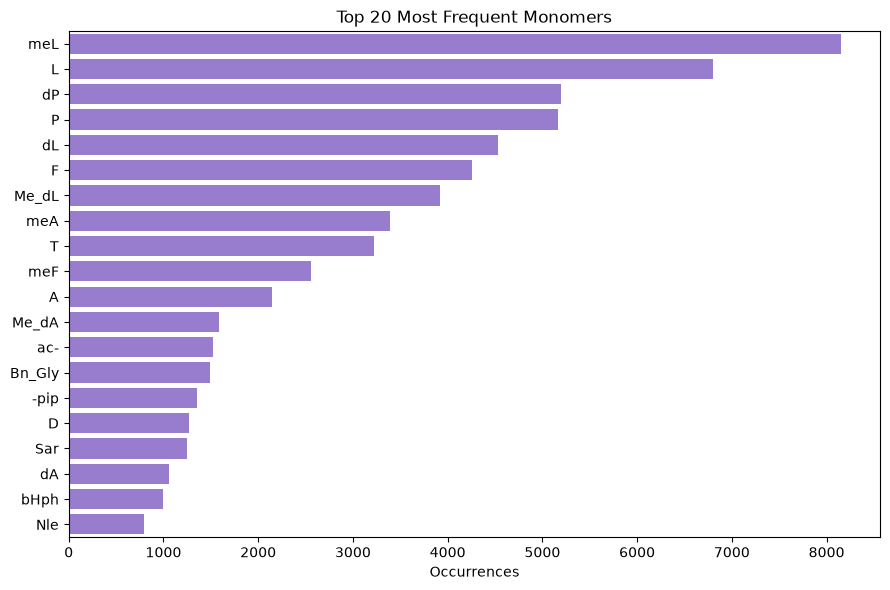

In [20]:
# top 20 most frequent monomers
top_monomers = monomer_df.head(20)

plt.figure(figsize=(9, 6))
sns.barplot(
    data=top_monomers,
    x="Count", y="Monomer",
    color="mediumpurple"
)

plt.title("Top 20 Most Frequent Monomers")
plt.xlabel("Occurrences")
plt.ylabel("")
plt.tight_layout()
plt.show()


In [ ]:

# monomer frequency alone doesnt tell us how many peptides contain each modification
# so for exacmpl one peptide containing five N-methylated residues contributes five occurrences to the frequency chart, but it is still only one peptide record.
# We need peptide-level statistics for each monomer. For example, how many peptides contain at least one N-methylated residue? How many peptides contain at least one D-amino acid? etc.

In [22]:
# load monomer reference table 
monomers = pd.read_csv(
    "../data/raw/CycPeptMPDB_Monomer_All.csv",
    encoding="utf-8-sig",
    low_memory=False
)

print("Shape:", monomers.shape)
print("Unique symbols:", monomers["Symbol"].nunique())

display(
    monomers[
        ["Symbol", "Natural_Analog", "Monomer_Type",
         "IUPAC_Name", "replaced_SMILES"]
    ].head(10)
)


Shape: (385, 229)
Unique symbols: 385


,Symbol,Natural_Analog,Monomer_Type,IUPAC_Name,replaced_SMILES
0,A,A,Backbone,(2S)-2-aminopropanoic acid,C[C@H](N)C(=O)O
1,dA,A,Backbone,(2R)-2-aminopropanoic acid,C[C@@H](N)C(=O)O
2,meA,A,Backbone,(2S)-2-(methylamino)propanoic acid,CN[C@@H](C)C(=O)O
3,Me_dA,A,Backbone,(2R)-2-(methylamino)propanoic acid,CN[C@H](C)C(=O)O
4,Ala(tBu),A,Backbone,"(2S)-2-amino-4,4-dimethylpentanoic acid",CC(C)(C)C[C@H](N)C(=O)O
5,Ala(indol-2-yl),A,Backbone,(2S)-2-amino-3-(1H-indol-2-yl)propanoic acid,N[C@@H](Cc1cc2ccccc2[nH]1)C(=O)O
6,dAla(indol-2-yl),A,Backbone,(2R)-2-amino-3-(1H-indol-2-yl)propanoic acid,N[C@H](Cc1cc2ccccc2[nH]1)C(=O)O
7,Me_Ala(indol-2-yl),A,Backbone,(2S)-3-(1H-indol-2-yl)-2-(methylamino)propanoi...,CN[C@@H](Cc1cc2ccccc2[nH]1)C(=O)O
8,Ala(5-Tet),A,Backbone,(2S)-2-amino-3-(2H-tetrazol-5-yl)propanoic acid,N[C@@H](Cc1nnn[nH]1)C(=O)O
9,Abu,X,Backbone,(2S)-2-aminobutyric acid,CC[C@H](N)C(=O)O


In [23]:
# check monomer vocabulary coverage
dataset_monomers = set(monomer_counts)
reference_monomers = set(monomers["Symbol"].dropna())

matched = dataset_monomers & reference_monomers
unmatched = dataset_monomers - reference_monomers

print("Dataset monomers:", len(dataset_monomers))
print("Matched to reference:", len(matched))
print("Unmatched:", len(unmatched))

print("\nUnmatched symbols:")
print(sorted(unmatched))


Dataset monomers: 385
Matched to reference: 385
Unmatched: 0

Unmatched symbols:
[]


In [24]:
# check for common backbone modification states
symbols = ["A", "dA", "meA", "Me_dA",
           "L", "dL", "meL", "Me_dL"]

cols = ["Symbol", "Natural_Analog", "Monomer_Type",
        "IUPAC_Name", "replaced_SMILES"]

display(monomers[monomers["Symbol"].isin(symbols)][cols])


,Symbol,Natural_Analog,Monomer_Type,IUPAC_Name,replaced_SMILES
0,A,A,Backbone,(2S)-2-aminopropanoic acid,C[C@H](N)C(=O)O
1,dA,A,Backbone,(2R)-2-aminopropanoic acid,C[C@@H](N)C(=O)O
2,meA,A,Backbone,(2S)-2-(methylamino)propanoic acid,CN[C@@H](C)C(=O)O
3,Me_dA,A,Backbone,(2R)-2-(methylamino)propanoic acid,CN[C@H](C)C(=O)O
99,L,L,Backbone,(2S)-2-amino-4-methylpentanoic acid,CC(C)C[C@H](N)C(=O)O
100,dL,L,Backbone,(2R)-2-amino-4-methylpentanoic acid,CC(C)C[C@@H](N)C(=O)O
101,meL,L,Backbone,(2S)-4-methyl-2-(methylamino)pentanoic acid,CN[C@@H](CC(C)C)C(=O)O
102,Me_dL,L,Backbone,(2R)-4-methyl-2-(methylamino)pentanoic acid,CN[C@H](CC(C)C)C(=O)O


In [ ]:

# verify modification examples (alanine and leucine)
nme_tokens = {"meA", "Me_dA", "meL", "Me_dL"}
d_tokens = {"dA", "Me_dA", "dL", "Me_dL"}

# classify peptide records
has_nme = sequences.apply(lambda seq: any(m in nme_tokens for m in seq))
has_d = sequences.apply(lambda seq: any(m in d_tokens for m in seq))

summary = pd.Series({
    "N-methylated": has_nme.sum(),
    "D-residues": has_d.sum(),
    "Both": (has_nme & has_d).sum(),
    "Neither": (~has_nme & ~has_d).sum()
})

display(summary.to_frame("Peptide records"))


,Peptide records
N-methylated,7252
D-residues,5461
Both,4749
Neither,502


In [26]:

# monomer types and natural analogs
print("Monomer types:")
display(monomers["Monomer_Type"].value_counts(dropna=False))

print("\nMost common natural analogs:")
display(monomers["Natural_Analog"].value_counts(dropna=False).head(20))

# inspect a subset of modified monomers
symbols = ["dP", "meF", "meV", "Me_dL", "Sar", "Abu"]

display(
    monomers.loc[
        monomers["Symbol"].isin(symbols),
        ["Symbol", "Natural_Analog", "Monomer_Type", "IUPAC_Name"]
    ]
)


Monomer types:


Monomer_Type
Backbone    374
Terminal     11
Name: count, dtype: int64


Most common natural analogs:


Natural_Analog
X    78
F    63
G    47
A    34
S    29
L    19
V    15
K    13
P    12
Y    11
Q    10
I     8
W     8
N     7
D     6
T     6
E     5
C     4
R     4
H     3
Name: count, dtype: int64

,Symbol,Natural_Analog,Monomer_Type,IUPAC_Name
9,Abu,X,Backbone,(2S)-2-aminobutyric acid
38,meF,F,Backbone,(2S)-2-(methylamino)-3-phenylpropanoic acid
102,Me_dL,L,Backbone,(2R)-4-methyl-2-(methylamino)pentanoic acid
129,dP,P,Backbone,(2R)-pyrrolidine-2-carboxylic acid
162,Sar,G,Backbone,2-(methylamino)acetic acid
174,meV,V,Backbone,(2S)-3-methyl-2-(methylamino)butanoic acid


In [27]:
type_map = monomers.set_index("Symbol")["Monomer_Type"].to_dict()

type_counts = Counter(
    type_map[m]
    for seq in sequences
    for m in seq
)

display(pd.Series(type_counts, name="Occurrences"))

# List terminal monomers
display(
    monomers.loc[
        monomers["Monomer_Type"] == "Terminal",
        ["Symbol", "Natural_Analog", "IUPAC_Name"]
    ]
)


Backbone    68166
Terminal     2936
Name: Occurrences, dtype: int64

,Symbol,Natural_Analog,IUPAC_Name
305,ac-,X,acetic acid
306,deca-,X,decanoic acid
307,glyco-,G,2-hydroxyacetic acid
308,medl-,L,(2R)-4-methyl-2-(methylamino)pentanoic acid
309,-pip,X,piperidine
310,Mono21-,X,"(2E,4E)-6-oxohexa-2,4-dienoic acid"
311,Mono22-,X,"(4Z,6E)-2,3-dihydroxy-2,6,8-trimethyldeca-4,6-..."
328,-pyrro,X,pyrrolidine
355,-nme2,X,N-methylmethanamine
371,-mor,X,morpholine-4-carboxamide


In [28]:

# Count terminal monomers per peptide
terminal_counts = sequences.apply(
    lambda seq: sum(type_map[m] == "Terminal" for m in seq)
)

display(pd.crosstab(
    df.loc[terminal_counts.index, "Molecule_Shape"],
    terminal_counts,
    rownames=["Topology"],
    colnames=["Terminal monomers"]
))


Terminal monomers,0,1
Topology,,
Circle,5530,0
Lariat,0,2936


In [30]:

backbone["NMe_candidate"] = backbone["IUPAC_Name"].str.contains(
    r"2-\(methylamino\)|2-\(N-methylamino\)",
    case=False, na=False
)

print("Candidate backbone N-methylated monomers:",
      backbone["NMe_candidate"].sum())

display(
    backbone.loc[
        backbone["NMe_candidate"],
        ["Symbol", "IUPAC_Name"]
    ]
)


Candidate backbone N-methylated monomers: 58


,Symbol,IUPAC_Name
2,meA,(2S)-2-(methylamino)propanoic acid
3,Me_dA,(2R)-2-(methylamino)propanoic acid
7,Me_Ala(indol-2-yl),(2S)-3-(1H-indol-2-yl)-2-(methylamino)propanoi...
11,Me_Abu,(2S)-2-(methylamino)butanoic acid
12,Me_dAbu,(2R)-2-(methylamino)butanoic acid
13,Me_Abu(morpholino),(2S)-2-(methylamino)-4-morpholin-4-ylbutanoic ...
24,Me_Cha,(2S)-3-cyclohexyl-2-(methylamino)propanoic acid
26,meD,(2S)-2-(methylamino)butanedioic acid
38,meF,(2S)-2-(methylamino)-3-phenylpropanoic acid
39,Me_dF,(2R)-2-(methylamino)-3-phenylpropanoic acid


### Q. How many peptides share the same side chains but differ in backbone modifications?

### Q. Are there enough matched peptide series to evaluate PepGate?